# FP32 vs INT8 (PTQ, QAT) on the test set

Compares the three `results/eval_<label>/` runs written by `evaluate_model.ipynb`. Nothing is re-measured here.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

LABELS = ["FP32", "INT8-PTQ", "INT8-QAT"]
SHORT = {"FP32": "FP32", "INT8-PTQ": "PTQ", "INT8-QAT": "QAT"}
COLORS = {"FP32": "#1f77b4", "INT8-PTQ": "#ff7f0e", "INT8-QAT": "#2ca02c"}
OUT_DIR = Path("results/comparison")
OUT_DIR.mkdir(parents=True, exist_ok=True)
N_BOOT = 2000

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "font.size": 9,
})

def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(OUT_DIR / f"{name}.png", dpi=300, bbox_inches="tight")

metrics = {l: json.load(open(f"results/eval_{l}/metrics.json")) for l in LABELS}
preds = {l: pd.read_csv(f"results/eval_{l}/predictions.csv") for l in LABELS}

## Checks

In [2]:
ref = preds["FP32"]
for l in LABELS[1:]:
    if not (preds[l]["image_id"].equals(ref["image_id"]) and preds[l]["true"].equals(ref["true"])):
        raise RuntimeError(f"{l} was evaluated on different test images than FP32: refusing to compare")

classes = [c[len("prob_"):] for c in ref.columns if c.startswith("prob_")]
idx = {c: i for i, c in enumerate(classes)}
y_true = ref["true"].map(idx).to_numpy()
y_pred = {l: preds[l]["predicted"].map(idx).to_numpy() for l in LABELS}
y_prob = {l: preds[l][[f"prob_{c}" for c in classes]].to_numpy() for l in LABELS}

SCORES = {  # computed from predictions.csv, used by the bootstrap
    "accuracy": lambda l, i: accuracy_score(y_true[i], y_pred[l][i]),
    "macro_f1": lambda l, i: f1_score(y_true[i], y_pred[l][i], average="macro", zero_division=0),
    "macro_auc_ovr": lambda l, i: roc_auc_score(y_true[i], y_prob[l][i], multi_class="ovr", average="macro",
                                                labels=list(range(len(classes)))),
}
everything = np.arange(len(y_true))
for l in LABELS:
    for m, fn in SCORES.items():
        if abs(fn(l, everything) - metrics[l]["performance"][m]) > 1e-9:
            raise RuntimeError(f"{l}: {m} from predictions.csv does not match metrics.json")
print(f"OK: same {len(y_true)} test images for all three models; predictions.csv matches metrics.json")

drift_note = ""
if Path("results/eval_session_drift.json").exists():
    drift = json.load(open("results/eval_session_drift.json"))
    if drift["stable"]:
        print(f"OK: timings stable during the session (within ±{drift['tolerance']:.0%})")
    else:
        drift_note = "latency drifted " + ", ".join(f"{SHORT[k]} {v:+.0%}" for k, v in drift["relative_change"].items()) \
                     + " during the session: costs are indicative only"
        print("WARNING:", drift_note)

OK: same 1035 test images for all three models; predictions.csv matches metrics.json
OK: timings stable during the session (within ±10%)


## Summary

Predictive metrics change in percentage points (pp); costs change in %.

In [3]:
def val(l, *path):
    node = metrics[l]
    for key in path:
        node = node[key]
    return node

ROWS = [  # (name, path, kind) kind: "score" in pp, "cost" lower is better, "gain" higher is better
    ("Accuracy", ("performance", "accuracy"), "score"),
    ("Balanced accuracy", ("performance", "balanced_accuracy"), "score"),
    ("Macro F1", ("performance", "macro_f1"), "score"),
    ("Macro AUC", ("performance", "macro_auc_ovr"), "score"),
    ("Melanoma recall", ("per_class", "mel", "recall"), "score"),
    ("Model size (MB)", ("efficiency", "model_size_mb"), "cost"),
    ("Latency, 1 image (ms, median)", ("efficiency", "latency_bs1_ms", "median"), "cost"),
    ("Throughput, batch 32 (img/s)", ("efficiency", "throughput_bs32_ips", "images_per_s"), "gain"),
    ("Peak memory, batch 32 (MB)", ("efficiency", "memory_mb", "bs32", "peak_over_baseline_mb"), "cost"),
    ("Energy (Wh / 1,000 images)", ("energy", "wh_per_1000_images"), "cost"),
    ("CO₂e (g / 1,000 images)", ("energy", "g_co2e_per_1000_images"), "cost"),
]

table = []
for name, path, kind in ROWS:
    v = {l: val(l, *path) for l in LABELS}
    row = {"metric": name, **{l: round(v[l], 4 if kind == "score" else 3) for l in LABELS}}
    for l in LABELS[1:]:
        if kind == "score":
            row[f"{SHORT[l]} vs FP32"] = f"{(v[l] - v['FP32']) * 100:+.1f} pp"
        else:
            ratio = v["FP32"] / v[l] if kind == "cost" else v[l] / v["FP32"]
            row[f"{SHORT[l]} vs FP32"] = f"{(v[l] / v['FP32'] - 1) * 100:+.0f}% ({ratio:.1f}x {'less' if kind == 'cost' else 'more'})"
    table.append(row)
table = pd.DataFrame(table)
table.to_csv(OUT_DIR / "comparison_table.csv", index=False)
table

,metric,FP32,INT8-PTQ,INT8-QAT,PTQ vs FP32,QAT vs FP32
0,Accuracy,0.8145,0.8126,0.8087,-0.2 pp,-0.6 pp
1,Balanced accuracy,0.6987,0.7075,0.6960,+0.9 pp,-0.3 pp
2,Macro F1,0.6862,0.6882,0.6748,+0.2 pp,-1.1 pp
3,Macro AUC,0.9531,0.9507,0.9547,-0.2 pp,+0.2 pp
4,Melanoma recall,0.6566,0.6768,0.7172,+2.0 pp,+6.1 pp
5,Model size (MB),42.7250,10.7970,10.7970,-75% (4.0x less),-75% (4.0x less)
6,"Latency, 1 image (ms, median)",24.0830,6.8340,6.6510,-72% (3.5x less),-72% (3.6x less)
7,"Throughput, batch 32 (img/s)",47.6280,186.2700,189.7190,+291% (3.9x more),+298% (4.0x more)
8,"Peak memory, batch 32 (MB)",394.1020,95.6330,95.7190,-76% (4.1x less),-76% (4.1x less)
9,"Energy (Wh / 1,000 images)",0.2940,0.0880,0.0890,-70% (3.4x less),-70% (3.3x less)


## Is the difference real? (paired bootstrap)

2,000 resamples of the test images, the same images for both models. "Yes" means the 95% CI of the difference excludes 0.

In [4]:
rng = np.random.default_rng(0)
resamples = rng.integers(0, len(y_true), size=(N_BOOT, len(y_true)))
boot_rows = []
for m, fn in SCORES.items():
    row = {"metric": m}
    for l in LABELS[1:]:
        diffs = [fn(l, i) - fn("FP32", i) for i in resamples
                 if m != "macro_auc_ovr" or len(np.unique(y_true[i])) == len(classes)]  # AUC needs every class
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        row[f"{SHORT[l]} - FP32 (pp)"] = round((fn(l, everything) - fn("FP32", everything)) * 100, 2)
        row[f"{SHORT[l]} 95% CI (pp)"] = f"[{lo * 100:+.2f}, {hi * 100:+.2f}]"
        row[f"{SHORT[l]} significant?"] = "yes" if not lo <= 0 <= hi else "no"
        row[f"_{SHORT[l]}_lo"], row[f"_{SHORT[l]}_hi"] = lo, hi
    boot_rows.append(row)
boot = pd.DataFrame(boot_rows)
boot.to_csv(OUT_DIR / "paired_bootstrap.csv", index=False)
boot[[c for c in boot.columns if not c.startswith("_")]]

,metric,PTQ - FP32 (pp),PTQ 95% CI (pp),PTQ significant?,QAT - FP32 (pp),QAT 95% CI (pp),QAT significant?
0,accuracy,-0.19,"[-1.26, +0.77]",no,-0.58,"[-1.84, +0.48]",no
1,macro_f1,0.20,"[-1.23, +1.74]",no,-1.14,"[-3.55, +1.06]",no
2,macro_auc_ovr,-0.24,"[-0.52, +0.00]",no,0.16,"[-0.32, +0.68]",no


## Prediction agreement with FP32

In [5]:
agreement = pd.DataFrame([{
    "model": l,
    "identical to FP32": f"{(y_pred[l] == y_pred['FP32']).mean() * 100:.1f}%",
    "fixed (FP32 wrong, now right)": int(((y_pred["FP32"] != y_true) & (y_pred[l] == y_true)).sum()),
    "broken (FP32 right, now wrong)": int(((y_pred["FP32"] == y_true) & (y_pred[l] != y_true)).sum()),
} for l in LABELS[1:]])
agreement.to_csv(OUT_DIR / "prediction_agreement.csv", index=False)
agreement

,model,identical to FP32,"fixed (FP32 wrong, now right)","broken (FP32 right, now wrong)"
0,INT8-PTQ,96.2%,13,15
1,INT8-QAT,95.4%,16,22


## Plots

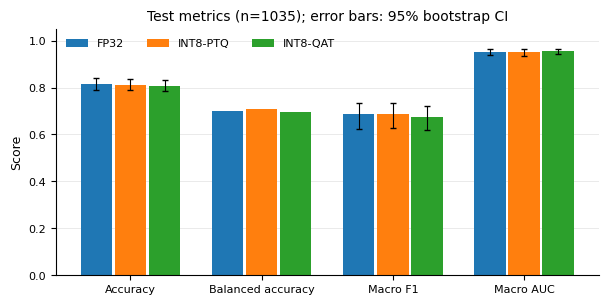

In [6]:
# 1. Headline metrics with each model's 95% bootstrap CI
pm = [("accuracy", "Accuracy"), ("balanced_accuracy", "Balanced accuracy"), ("macro_f1", "Macro F1"),
      ("macro_auc_ovr", "Macro AUC")]
x, w = np.arange(len(pm)), 0.26
fig, ax = plt.subplots(figsize=(7, 3.2))
for k, l in enumerate(LABELS):
    perf = metrics[l]["performance"]
    v = np.array([perf[m] for m, _ in pm])
    pos = x + (k - 1) * w
    ax.bar(pos, v, w * 0.92, color=COLORS[l], label=l)
    has_ci = [j for j, (m, _) in enumerate(pm) if m in perf["ci95"]]  # balanced accuracy has no CI: no error bar
    ax.errorbar(pos[has_ci], v[has_ci], fmt="none", ecolor="black", elinewidth=0.8, capsize=2,
                yerr=[[perf[pm[j][0]] - perf["ci95"][pm[j][0]][0] for j in has_ci],
                      [perf["ci95"][pm[j][0]][1] - perf[pm[j][0]] for j in has_ci]])
ax.set_xticks(x)
ax.set_xticklabels([n for _, n in pm])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title(f"Test metrics (n={len(y_true)}); error bars: 95% bootstrap CI")
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.grid(axis="x", visible=False)
save_fig(fig, "1_metrics")
plt.show()

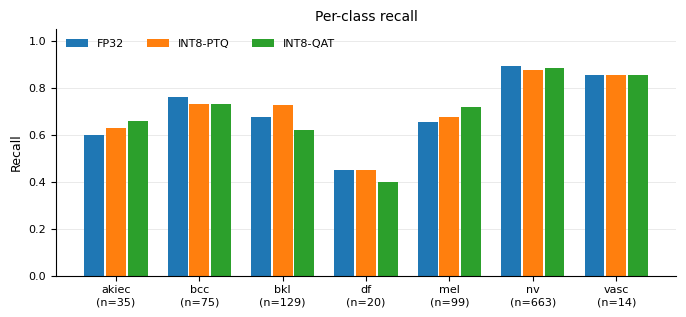

In [7]:
# 2. Per-class recall
xc = np.arange(len(classes))
support = [int((y_true == idx[c]).sum()) for c in classes]
fig, ax = plt.subplots(figsize=(8, 3.2))
for k, l in enumerate(LABELS):
    ax.bar(xc + (k - 1) * w, [metrics[l]["per_class"][c]["recall"] for c in classes], w * 0.92, color=COLORS[l], label=l)
ax.set_xticks(xc)
ax.set_xticklabels([f"{c}\n(n={n})" for c, n in zip(classes, support)])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Recall")
ax.set_title("Per-class recall")
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.grid(axis="x", visible=False)
save_fig(fig, "2_per_class_recall")
plt.show()

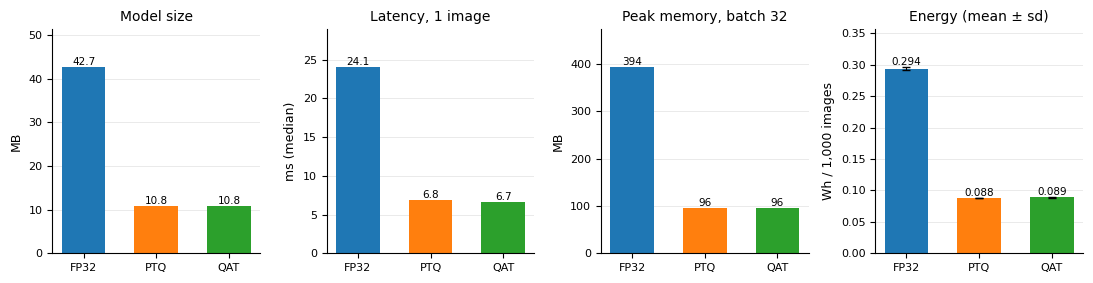

In [8]:
# 3. Costs
panels = [("Model size", "MB", ("efficiency", "model_size_mb"), None, "{:.1f}"),
          ("Latency, 1 image", "ms (median)", ("efficiency", "latency_bs1_ms", "median"), None, "{:.1f}"),
          ("Peak memory, batch 32", "MB", ("efficiency", "memory_mb", "bs32", "peak_over_baseline_mb"), None, "{:.0f}"),
          ("Energy (mean ± sd)", "Wh / 1,000 images", ("energy", "wh_per_1000_images"), ("energy", "wh_per_1000_images_std"), "{:.3f}")]
fig, axes = plt.subplots(1, 4, figsize=(11, 2.9))
for ax, (title, ylabel, path, sd_path, fmt) in zip(axes, panels):
    v = [val(l, *path) for l in LABELS]
    sd = [val(l, *sd_path) for l in LABELS] if sd_path else None
    ax.bar([SHORT[l] for l in LABELS], v, color=[COLORS[l] for l in LABELS], width=0.6,
           yerr=sd, capsize=3, error_kw={"elinewidth": 0.8, "ecolor": "black"})
    for i, (vi, si) in enumerate(zip(v, sd or [0] * 3)):
        ax.text(i, vi + si, fmt.format(vi), ha="center", va="bottom", fontsize=7.5)
    ax.set_ylim(0, max(a + b for a, b in zip(v, sd or [0] * 3)) * 1.2)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
if drift_note:
    fig.suptitle("Note: " + drift_note, fontsize=8, color="#b00000", y=1.04)
fig.tight_layout()
save_fig(fig, "3_costs")
plt.show()

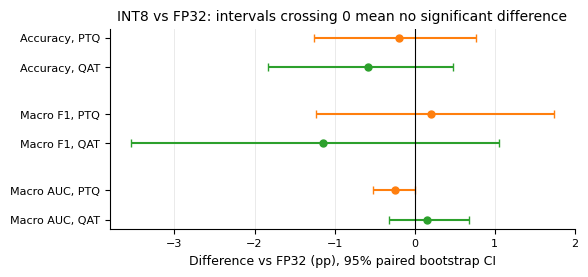

In [9]:
# 4. INT8 minus FP32, with the paired 95% CI: the plot that answers "did quantization change the score?"
names = {"accuracy": "Accuracy", "macro_f1": "Macro F1", "macro_auc_ovr": "Macro AUC"}
fig, ax = plt.subplots(figsize=(6, 2.6))
ticks = []
for j, m in enumerate(names):
    r = boot[boot["metric"] == m].iloc[0]
    for k, l in enumerate(LABELS[1:]):
        y = j * 2.6 + k
        d, lo, hi = r[f"{SHORT[l]} - FP32 (pp)"], r[f"_{SHORT[l]}_lo"] * 100, r[f"_{SHORT[l]}_hi"] * 100
        ax.errorbar(d, y, xerr=[[d - lo], [hi - d]], fmt="o", color=COLORS[l], capsize=3, markersize=5)
        ticks.append((y, f"{names[m]}, {SHORT[l]}"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks([t for t, _ in ticks])
ax.set_yticklabels([n for _, n in ticks])
ax.invert_yaxis()
ax.set_xlabel("Difference vs FP32 (pp), 95% paired bootstrap CI")
ax.set_title("INT8 vs FP32: intervals crossing 0 mean no significant difference")
ax.grid(axis="y", visible=False)
save_fig(fig, "4_differences_vs_fp32")
plt.show()